# Retail Demand Forecasting & Inventory Intelligence
## Phase 3 - Feature Engineering: a leakage-safe modeling table for 16-day forecasting

**Business question.** A supermarket chain must order stock 16 days ahead. For every one of the 54 stores x 33 product families
(1,782 series) we need a daily unit-sales forecast for the next 16 days, made *on the evening of the last observed day* (the "forecast origin").

**What this notebook produces** (all written to `out/`):

| file | content |
|---|---|
| `modeling_table.parquet` | the clean training / validation table - one row per (forecast origin, horizon, store, family) |
| `test_features.parquet` | the same features for the real forecast origin (2017-08-15) with the Kaggle `id` for submission |
| `feature_dictionary.csv` | every feature: group, definition, availability at forecast time, leakage risk, test-first priority |
| `model_config.json` | feature lists, categorical columns, target, validation folds - read by the next phase |
| `lookups.csv` | code -> label for every integer-encoded column (family, store type, city, holiday type, event) |

**What this notebook does *not* do:** train any model. Section 9 only scores three trivial "no-model" baselines
(computed from columns of the table) so that the validation design is proven to work and the next phase has a bar to beat.

Everything is built by `favorita.py` (shared with the EDA notebook), so the EDA decisions - which zeros are demand, which are not - are applied once, in one place.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import copy, json, os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import favorita as fv
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
fv.set_style()
os.makedirs("figs", exist_ok=True); os.makedirs("out", exist_ok=True)
BLUE, ORANGE, MUTED, INK2 = fv.BLUE, fv.ORANGE, fv.MUTED, fv.INK2
def finish(fig, name):
    fig.tight_layout(rect=[0, 0, 1, 0.94] if fig._suptitle is not None else None)
    fig.savefig(f"figs/{name}.png", dpi=110); plt.show()
def ftitle(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=12.5, fontweight="bold")
import gc, ctypes
def free_mem():                                     # the table is ~1.5 GB: hand memory back to the OS after heavy cells
    gc.collect()
    try: ctypes.CDLL("libc.so.6").malloc_trim(0)
    except OSError: pass

raw = fv.load_raw("data")
P = fv.Panel(raw)                                   # dense [day, store, family] arrays; 25-Dec stays NaN, zeros that are not demand are masked
H = fv.holiday_calendar(raw["hol"], P)              # store-specific holiday flags (local / regional / national, transfers resolved)
FB = fv.FeatureBuilder(P, H, raw["stores"])         # prefix sums built once; every feature read is indexed <= origin
Tt = P.n_train_days; T_ORIGIN = Tt - 1
print(f"panel {P.shape} | last observed day {P.dates[T_ORIGIN].date()} ({P.dates[T_ORIGIN].day_name()}) | test window {P.dates[Tt].date()} -> {P.dates[-1].date()}")

panel (1704, 54, 33) | last observed day 2017-08-15 (Tuesday) | test window 2017-08-16 -> 2017-08-31


## 1. Problem framing - how a real forecasting table is laid out

In a company the forecast is produced *once a week* (here: every Tuesday evening) and has to cover the next 16 days. That fixes three concepts:

* **Forecast origin `t`** - the last day whose sales are known. Everything the model may see is dated `<= t`, **plus** facts that are known in advance about the future days (calendar, holidays, planned promotions - the promo counts are columns of `test.csv`).
* **Horizon `h = 1..16`** - how many days after the origin the target day lies.
* **Target** - sales of that store x family on day `t + h`.

One row of the modeling table = one *(origin, horizon, store, family)*. Using **direct multi-horizon** rows (instead of one-step-ahead forecasts fed back into themselves) means the model is trained on exactly the situation it faces in production: at horizon 16 the newest sales it can see are 16 days old.
The real test origin is Tuesday **2017-08-15**; the training rows are built from historical Tuesdays so that every horizon and weekday pairing appears.

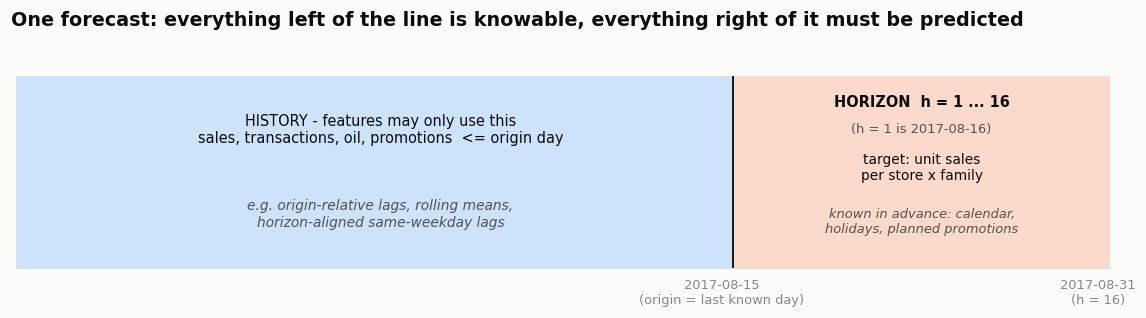

In [2]:
fig, ax = plt.subplots(figsize=(10.5, 2.9))
ax.axvspan(-30, 0.5, color="#cde2fb", zorder=0); ax.axvspan(0.5, 16.5, color="#fbd9cb", zorder=0)
ax.axvline(0.5, color=fv.INK, lw=1.2)
ax.text(-14.5, 0.72, "HISTORY - features may only use this\nsales, transactions, oil, promotions  <= origin day", ha="center", va="center", fontsize=9.5, color=fv.INK)
ax.text(-14.5, 0.28, "e.g. origin-relative lags, rolling means,\nhorizon-aligned same-weekday lags", ha="center", va="center", fontsize=9, color=INK2, style="italic")
ax.text(8.5, 0.86, "HORIZON  h = 1 ... 16", ha="center", va="center", fontsize=9.5, color=fv.INK, fontweight="bold")
ax.text(8.5, 0.72, f"(h = 1 is {P.dates[T_ORIGIN + 1].date()})", ha="center", va="center", fontsize=8.5, color=INK2)
ax.text(8.5, 0.52, "target: unit sales\nper store x family", ha="center", va="center", fontsize=9, color=fv.INK)
ax.text(8.5, 0.24, "known in advance: calendar,\nholidays, planned promotions", ha="center", va="center", fontsize=8.5, color=INK2, style="italic")
ax.set_xlim(-30, 16.5); ax.set_ylim(0, 1); ax.set_yticks([]); ax.grid(False)
ax.set_xticks([0, 16.5 - 0.5]); ax.set_xticklabels([f"{P.dates[T_ORIGIN].date()}\n(origin = last known day)", f"{P.dates[T_ORIGIN + 16].date()}\n(h = 16)"], fontsize=8.5)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ftitle(fig, "One forecast: everything left of the line is knowable, everything right of it must be predicted")
finish(fig, "fe_framing")

## 2. Scope decisions - what gets modeled, what gets a rule, what gets dropped

The EDA showed that a raw zero in this dataset can mean six different things. Feeding them all to a model as "demand = 0" would teach it noise, so the table applies these rules (all implemented in `favorita.py`):

| situation | evidence (EDA) | decision |
|---|---|---|
| Store not yet open (stores that opened after 2013-01-01) | all 33 families are 0 before the first sale | **Target masked (NaN) -> row dropped.** History features treat those days as *missing*, not as 0. |
| Store closed a full day / multi-day closure | all families 0 in an otherwise open store | **Masked** for target and history. |
| 25 December | no row exists in `train.csv` | **Not a zero.** Stays NaN in the calendar; never a target, never a lag value. (Not inside the test window, so no submission impact.) |
| Family not recorded (chain-wide outages / off-regime windows, e.g. BEVERAGES/PRODUCE recording gaps) | >= 5 families zero simultaneously for long runs; families whose median sales fall below 55% of their normal level on those days | **Masked** on those days for the affected families only. |
| Store x family that **never** sells (structural, e.g. BABY CARE in store 1) | zero for the entire history | **`rule_zero = 1`.** Forecast 0 by rule; excluded from model training. |
| Store x family **dormant**: no valid sale in the last 90 days (>= 45 valid days seen) | back-test precision ~96% that the next 16 days are all zero | **`rule_zero = 1`.** Forecast 0 by rule (checked in section 4). `SCHOOL AND OFFICE SUPPLIES` is exempt: its back-to-school peak sits inside the test window and it "wakes up" every August. |
| Live series that has a zero day (true zero demand) | a slow mover with an intermittent pattern | **Kept as 0.** This is real demand information. |
| Cold start (< 14 valid days in the last 28) | new stores / re-openings | **Not used for training** (the test origin has 28/28 valid days for all 1,782 combinations, so nothing is lost). |

**Answer to the "should zero-demand combinations be modeled?" question:** *no* for structural/dormant ones (a rule is cheaper, more accurate and cannot be beaten by any model - and they would dominate a tree's splits with meaningless zeros), *yes* for intermittent-but-alive series (the model has `roll_zero_rate_*`, `days_since_last_sale` to handle them).
The rule is a **separate, transparent layer** (`rule_zero`): the model only forecasts rows where `rule_zero == 0`; the final submission overwrites `rule_zero == 1` rows with 0.

## 3. Build the modeling table

* **Origins:** every Tuesday from 2013-04-02 (90 days of history required) to 2017-08-08. The last two Tuesdays have only a *partial* horizon (their 16th day lies in the test period) - they carry 14 and 7 real targets and are used only for the final re-fit.
* **Rows kept:** target observed (not masked, not 25-Dec) **and** `valid_days_28d >= 14`.
* **Compact types:** flags -> `int8`, counters -> `int16`, features -> `float32` (a 5M-row table stays under ~2 GB in memory).
* **NaN policy:** missing feature values (e.g. no year-ago value in the first year) are *left as NaN* - never filled with 0, because 0 is a meaningful sales value here. Tree libraries handle NaN natively; the sklearn Random Forest needs an explicit fill (see section 10).

In [3]:
import pyarrow as pa, pyarrow.parquet as pq
origins = [t for t in range(90, T_ORIGIN) if P.dates[t].dayofweek == 1]       # Tuesdays, last one = Tt-8 (partial horizon)
t0 = time.time(); n_raw = n_target = 0; writer = None
for t in origins:                                                             # stream origin by origin -> constant memory
    df = FB.origin_table(t)
    n_raw += len(df); n_target += int(df.y.notna().sum())
    tbl = pa.Table.from_pandas(df[df.y.notna() & (df.valid_days_28d >= 14)], preserve_index=False)
    writer = writer or pq.ParquetWriter("out/modeling_table.parquet", tbl.schema, compression="zstd")
    writer.write_table(tbl)
writer.close()
mt = pq.read_table("out/modeling_table.parquet").to_pandas(self_destruct=True)   # self_destruct: avoids holding a second copy in Arrow memory
pa.default_memory_pool().release_unused()
print(f"{len(origins)} Tuesday origins: {P.dates[origins[0]].date()} -> {P.dates[origins[-1]].date()} | built in {time.time() - t0:.0f}s")
print(f"candidate rows {n_raw:,} -> kept {len(mt):,} ({len(mt) / n_raw:.1%}) | {mt.shape[1]} columns | {mt.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")
mt.head(3).T.head(20)

228 Tuesday origins: 2013-04-02 -> 2017-08-08 | built in 21s
candidate rows 6,500,736 -> kept 4,918,427 (75.7%) | 93 columns | 1.46 GB in memory


,0,1,2
origin_date,2013-04-02 00:00:00,2013-04-02 00:00:00,2013-04-02 00:00:00
horizon,1,1,1
target_date,2013-04-03 00:00:00,2013-04-03 00:00:00,2013-04-03 00:00:00
store_nbr,1,1,1
family_id,0,2,5
store_type,3,3,3
store_cluster,13,13,13
city_id,18,18,18
state_id,12,12,12
lag_1d,7.000,2.000,265.593


In [4]:
# Where did the candidate rows go?  (audit trail of the two filters)
print(f"candidate rows {n_raw:,} -> observable target {n_target:,} ({n_target / n_raw:.1%}) -> also >= 14 valid days of history {len(mt):,} ({len(mt) / n_raw:.1%})")
print(f"  removed because the target is masked / not yet observed: {n_raw - n_target:,} | removed by the cold-start filter: {n_target - len(mt):,}")
print("rows per horizon (should be near-flat):", mt.groupby("horizon").size().div(1e3).round(0).astype(int).to_dict(), "(thousand rows)")
print("origins per year:", mt.drop_duplicates("origin_date").origin_date.dt.year.value_counts().sort_index().to_dict())

candidate rows 6,500,736 -> observable target 5,082,639 (78.2%) -> also >= 14 valid days of history 4,918,427 (75.7%)
  removed because the target is masked / not yet observed: 1,418,097 | removed by the cold-start filter: 164,212
rows per horizon (should be near-flat): {1: 311, 2: 310, 3: 309, 4: 311, 5: 308, 6: 311, 7: 311, 8: 307, 9: 306, 10: 304, 11: 307, 12: 304, 13: 307, 14: 307, 15: 303, 16: 302} (thousand rows)
origins per year: {2013: 40, 2014: 52, 2015: 52, 2016: 52, 2017: 32}


## 4. Evidence for the zero-demand rule (`rule_zero`)

The rule is evaluated on the five validation origins (defined in section 9) using only what was known at each origin. *Precision* = share of rule-flagged rows whose actual target really is 0; *sales lost* = units in flagged rows that the rule would forecast as 0 but that were sold, relative to all units sold in the fold.

In [5]:
rows = []
for name, vo in fv.FOLD_ORIGINS.items():
    d = mt[mt.origin_date == vo]
    fl = d[d.rule_zero == 1]
    rows.append({"fold": name, "origin": vo, "scored rows": len(d), "rule_zero rows": len(fl), "share of rows": len(fl) / len(d),
                 "precision (target = 0)": (fl.y == 0).mean(), "share of all zero rows caught": len(fl[fl.y == 0]) / max(int((d.y == 0).sum()), 1),
                 "units in flagged rows": float(fl.y.sum()), "units lost vs fold total": fl.y.sum() / d.y.sum()})
zr_tab = pd.DataFrame(rows).set_index("fold")
zr_tab.style.format({"scored rows": "{:,.0f}", "rule_zero rows": "{:,.0f}", "share of rows": "{:.1%}", "precision (target = 0)": "{:.1%}", "share of all zero rows caught": "{:.1%}",
                     "units in flagged rows": "{:,.0f}", "units lost vs fold total": "{:.4%}"})

,origin,scored rows,rule_zero rows,share of rows,precision (target = 0),share of all zero rows caught,units in flagged rows,units lost vs fold total
fold,,,,,,,,
F1_seasonal_twin,2016-08-16,"26,272",842,3.2%,99.5%,25.2%,7,0.0001%
F2_holiday_heavy,2017-04-04,"27,984","1,168",4.2%,99.4%,30.4%,11,0.0001%
F3_mid_2017,2017-05-30,"28,512","1,168",4.1%,100.0%,29.2%,0,0.0000%
F4_recent,2017-07-11,"28,512","1,248",4.4%,100.0%,29.5%,0,0.0000%
F5_latest,2017-07-25,"28,512","1,264",4.4%,99.4%,29.8%,12,0.0001%


In [6]:
# what is inside the flagged group, and what is left for the model?
tw = (mt.origin_date >= "2015-07-01").values; rz = (mt.rule_zero == 1).values; y0 = (mt.y == 0).values
print(f"training window rows (origin >= 2015-07-01): {tw.sum():,}")
print(f"  rule_zero = 1 : {rz[tw].mean():.1%} of rows  | zero targets among them: {y0[tw & rz].mean():.1%}")
print(f"  rule_zero = 0 : {(~rz[tw]).mean():.1%} of rows  | zero targets among them: {y0[tw & ~rz].mean():.1%}  (real intermittent demand - kept)")
act = pd.read_csv("store_family_activity_status.csv") if os.path.exists("store_family_activity_status.csv") else None
if act is not None:
    print("\nactivity status of the 1,782 combinations at the real origin (2017-08-15):"); print(act.status.value_counts().to_string())

training window rows (origin >= 2015-07-01): 2,955,742
  rule_zero = 1 : 3.9% of rows  | zero targets among them: 99.2%
  rule_zero = 0 : 96.1% of rows  | zero targets among them: 10.4%  (real intermittent demand - kept)

activity status of the 1,782 combinations at the real origin (2017-08-15):
status
regular         1544
intermittent     158
never sold        53
dormant           27


**Insight - zero-demand combinations.** On every validation origin the rule flags 3-4% of the rows (80 of 1,782 combinations at the real origin: 53 that have never sold plus 27 dormant ones). **99.4-100% of the flagged target days really are zero**, and the units sold inside flagged rows are negligible (0-12 units per fold, ~0.0001% of the fold's volume). The stricter series-level test used in the EDA - *all* 16 days zero - gives ~96%; the day-level precision is higher because the few "wake-ups" are mostly single days.
The rule catches only about 25-30% of all zero rows: the other ~70% are zero days of live, intermittent series - genuine demand information that stays in the table (in the training window 10% of the modeled rows are zeros, vs 99% zeros among the flagged rows). Hence `roll_zero_rate_*` and `days_since_last_sale` are features, and the decision is: **model only `rule_zero == 0`; score everything.**

## 5. Feature dictionary - every column, its group, and when it is knowable

The dictionary is *code*, not prose: the notebook asserts that it covers **exactly** the columns of the table, so documentation and data can never drift apart.
`availability` states the latest moment the information exists: **origin** = end of the origin day `t`; **advance** = known before `t` about the target day (calendar, holiday list, planned promotion counts - all in `test.csv`).
`priority`: **1** = test first, **2** = add in the second round, **3** = ablation candidates (test last; may add noise or drift).

In [7]:
G = {  # group -> purpose
 "A. Horizon & calendar": "Tell the model WHICH day is being predicted: weekday shape (Sun/Sat peaks), pay-day cycle (15th / month-end), seasonality, and how far ahead it is.",
 "B. Store & product identity": "Let the model learn persistent differences between stores (format, size, city) and product families - the level a series lives at.",
 "C. Holidays & events": "National / regional / local holidays resolved to each store's city and state, transfers, bridges, work-days and one-off events; the run-up and after-effects.",
 "D. Promotions": "Planned promotion counts for the target day (known in advance) and how unusual they are versus the series' own recent promo level.",
 "E. Origin-relative lags": "The most recent sales the model can see at the origin: recency of demand level. Identical for all horizons.",
 "F. Horizon-aligned same-weekday lags": "Sales on the same weekday as the target day, taken from the newest weeks that are <= origin. Removes the weekday effect from the level signal for EVERY horizon.",
 "G. Rolling level": "Smoothed recent demand level (short / medium / long windows) - robust baseline that absorbs day-to-day noise.",
 "H. Volatility": "How noisy the series is. Lets the model know when the recent level is reliable and when a forecast should be conservative.",
 "I. Growth & year-ago": "Direction of the trend (short vs long window) and where the series stood one year ago (annual seasonality, e.g. Christmas, back-to-school).",
 "J. Activity & intermittency": "Distinguish live, slow-moving, intermittent and dying series; supports the dormant rule.",
 "K. Store-level context": "Store total demand trend and maturity - borrows strength across the 33 families of a store.",
 "L. Store transactions (lagged)": "Foot-traffic trend of the store, ONLY up to the origin day. Same-day transactions are never used (they are unknown at forecast time).",
 "M. Family-level context": "Chain-wide trend of the product family and the store's share of it.",
 "N. Macro": "Oil price (proxy for Ecuador's economy) as of the origin day. Tested last: EDA found weak, indirect value.",
}
D = []   # name, group, definition, availability, leakage_risk, priority
def add(g, rows):
    for name, definition, avail, risk, pri in rows: D.append((name, g, definition, avail, risk, pri))

add("A. Horizon & calendar", [
 ("horizon", "Days between origin and target day (1..16)", "advance", "none", 1),
 ("dow", "Weekday of the target day (0=Mon..6=Sun)", "advance", "none", 1),
 ("is_weekend", "Target day is Sat/Sun", "advance", "none", 2),
 ("day_of_month", "Day of month of the target day", "advance", "none", 1),
 ("week_of_year", "ISO week of the target day", "advance", "none", 2),
 ("month", "Month of the target day", "advance", "none", 2),
 ("year", "Calendar year of the target day", "advance", "trees cannot extrapolate a new year; behaves like a time index", 3),
 ("is_payday", "Target day is the 15th or month-end (public-sector pay days)", "advance", "none", 1),
 ("days_to_payday", "Days until the next pay day", "advance", "none", 2),
 ("days_since_payday", "Days since the last pay day", "advance", "none", 2)])
add("B. Store & product identity", [
 ("store_nbr", "Store number (1..54)", "advance", "none", 1),
 ("family_id", "Product family code (0..32, see lookups.csv)", "advance", "none", 1),
 ("store_type", "Store type A-E (coded)", "advance", "none", 2),
 ("store_cluster", "Store cluster (1..17)", "advance", "none", 2),
 ("city_id", "City (coded)", "advance", "none; near-duplicate of store_nbr", 3),
 ("state_id", "State (coded)", "advance", "none; near-duplicate of store_nbr", 3)])
add("C. Holidays & events", [
 ("hol_national", "National holiday on the target day (transfers resolved)", "advance", "none", 1),
 ("hol_regional", "Regional (state-level) holiday matching the store's state", "advance", "none", 1),
 ("hol_local", "Local (city-level) holiday matching the store's city", "advance", "none", 1),
 ("hol_any", "Any of the three above", "advance", "none", 1),
 ("bridge", "Bridge day (extra day off attached to a holiday)", "advance", "none", 2),
 ("additional", "Additional holiday day", "advance", "none", 2),
 ("work_day", "Make-up working day (a Saturday worked to compensate a bridge)", "advance", "none", 2),
 ("hol_type", "Highest-priority holiday type code (0 none, 1 Holiday, 2 Transfer, 3 Bridge, 4 Additional, 5 Work Day)", "advance", "none", 2),
 ("event", "One-off event code (Mother's Day, Black Friday, Cyber Monday, World Cup, earthquake)", "advance", "none", 2),
 ("days_to_holiday", "Days to the store's next holiday (capped at 30)", "advance", "none", 2),
 ("days_since_holiday", "Days since the store's last holiday (capped at 30)", "advance", "none", 2),
 ("pre_holiday", "Day before a holiday (stock-up effect)", "advance", "none", 2),
 ("post_holiday", "Day after a holiday", "advance", "none", 2)])
add("D. Promotions", [
 ("onpromotion", "Number of items of the family on promotion in the store on the target day", "advance", "promo policy drifts over time (coverage 0% in 2013 -> ~47% in 2017); use recent training data", 1),
 ("promo_flag", "onpromotion > 0", "advance", "same drift as above", 1),
 ("promo_vs_28d", "onpromotion minus the store x family's average promo count over the last 28 valid days", "advance + origin", "none", 1),
 ("promo_ratio_28d", "onpromotion / (recent promo mean + 1)", "advance + origin", "none", 2),
 ("promo_mean_28d", "Mean onpromotion over the last 28 valid days (<= origin)", "origin", "none", 2),
 ("promo_days_share_28d", "Share of the last 28 valid days with a promotion", "origin", "none", 2),
 ("fam_promo_share_D", "Share of the 54 stores promoting this family on the target day (chain-wide campaign)", "advance", "same drift", 2),
 ("store_promo_share_D", "Share of the 33 families promoted in this store on the target day", "advance", "same drift", 2)])
add("E. Origin-relative lags", [
 ("lag_1d", "Sales on the origin day", "origin", "none (index = t)", 1),
 ("lag_7d", "Sales 6 days before the origin (7 days before the first forecast day)", "origin", "none", 1),
 ("lag_14d", "Sales 13 days before the origin", "origin", "none", 1),
 ("lag_28d", "Sales 27 days before the origin", "origin", "none", 2)])
add("F. Horizon-aligned same-weekday lags", [
 ("sd_lag_1", "Sales on the newest same-weekday date <= origin (i.e. target - 7*ceil(h/7))", "origin", "index asserted <= t for every horizon (section 7)", 1),
 ("sd_lag_2", "Same weekday, one week earlier than sd_lag_1", "origin", "none", 1),
 ("sd_lag_3", "Same weekday, two weeks earlier", "origin", "none", 1),
 ("sd_lag_4", "Same weekday, three weeks earlier", "origin", "none", 1),
 ("sd_mean_4", "Mean of sd_lag_1..4 (ignores masked days)", "origin", "none", 1),
 ("sd_mean_8", "Mean of the 8 newest same-weekday values", "origin", "none", 1),
 ("dow_ratio_8", "sd_mean_8 / 91-day mean: how strong this weekday is for this series (series-specific weekday amplitude)", "origin", "none", 1)])
add("G. Rolling level", [
 ("roll_mean_7d", "Mean sales over the last 7 valid days ending at the origin", "origin", "windows end at t", 1),
 ("roll_mean_14d", "Mean over the last 14 days", "origin", "windows end at t", 1),
 ("roll_mean_28d", "Mean over the last 28 days", "origin", "windows end at t", 1),
 ("roll_mean_56d", "Mean over the last 56 days", "origin", "windows end at t", 2),
 ("roll_median_28d", "Median over the last 28 days (robust to spikes)", "origin", "windows end at t", 2)])
add("H. Volatility", [
 ("roll_std_7d", "Std of sales over 7 days", "origin", "none", 2),
 ("roll_std_14d", "Std over 14 days", "origin", "none", 2),
 ("roll_std_28d", "Std over 28 days", "origin", "none", 2),
 ("roll_std_91d", "Std over 91 days", "origin", "none", 2),
 ("cv_28d", "Coefficient of variation (std / mean), 28 days", "origin", "none", 2),
 ("cv_91d", "Coefficient of variation, 91 days", "origin", "none", 2)])
add("I. Growth & year-ago", [
 ("growth_7_vs_28", "7-day mean / 28-day mean (momentum)", "origin", "none", 2),
 ("growth_28_vs_prev28", "Last 28 days / the 28 days before", "origin", "none", 2),
 ("growth_28_vs_91", "28-day mean / 91-day mean", "origin", "none", 2),
 ("yoy_lag_364", "Sales on the same weekday one year (364 days) before the target day", "origin", "index = target - 364 <= origin", 2),
 ("yoy_mean_15d", "Mean of the 15 days centred on that year-ago date (annual seasonality)", "origin", "index <= origin", 1),
 ("yoy_trend_28d", "Current 28-day mean / the same 28 days one year earlier (like-for-like growth)", "origin", "none", 2)])
add("J. Activity & intermittency", [
 ("roll_zero_rate_28d", "Share of valid days with zero sales, last 28", "origin", "none", 1),
 ("roll_zero_rate_91d", "Same, last 91 days", "origin", "none", 2),
 ("valid_days_28d", "Number of unmasked days in the last 28 (data coverage / cold-start indicator)", "origin", "depends on the offline masks (section 7, risk R3)", 2),
 ("days_since_last_sale", "Days since the last day with sales > 0", "origin", "none", 1),
 ("sf_zero_rate_all", "Zero rate over the full history up to the origin", "origin", "none", 2),
 ("sf_age_days", "Days since the combination's first sale", "origin", "none", 2),
 ("sf_mean_91d", "Mean sales over 91 days (long-run level)", "origin", "none", 2),
 ("sf_mean_all", "Mean sales over the whole history up to the origin (Store x Family historical average)", "origin", "expanding window, no future", 2)])
add("K. Store-level context", [
 ("store_mean_7d", "Store's mean daily total sales, last 7 days (stable families only)", "origin", "none", 2),
 ("store_mean_28d", "Store's mean daily total sales, last 28 days", "origin", "none", 2),
 ("store_growth_7_vs_28", "Store momentum (7d / 28d)", "origin", "none", 2),
 ("store_growth_28_vs_91", "Store trend (28d / 91d)", "origin", "none", 2),
 ("store_age_days", "Days since the store's first sale (maturity)", "origin", "none", 3)])
add("L. Store transactions (lagged)", [
 ("store_tx_mean_7d", "Mean daily transactions, last 7 days up to the origin", "origin", "same-day transactions are NEVER used", 3),
 ("store_tx_mean_28d", "Mean daily transactions, last 28 days", "origin", "same", 3),
 ("store_tx_growth_7_vs_28", "Transactions momentum", "origin", "same", 3),
 ("store_sales_per_tx_28d", "Units per transaction, last 28 days (basket size)", "origin", "same", 3)])
add("M. Family-level context", [
 ("fam_mean_7d", "Chain-wide mean daily sales of the family, last 7 days", "origin", "none", 2),
 ("fam_mean_28d", "Chain-wide mean daily sales of the family, last 28 days", "origin", "none", 2),
 ("fam_growth_7_vs_28", "Family momentum", "origin", "none", 2),
 ("sf_share_of_family_28d", "This store's share of the family's chain-wide sales", "origin", "none", 2)])
add("N. Macro", [
 ("oil_price", "Oil price on the origin day (forward-filled over weekends)", "origin", "only the 2013-01-01 value is back-filled", 3),
 ("oil_pct_chg_28d", "% change of the oil price over the 28 days to the origin", "origin", "none", 3)])

fd = pd.DataFrame(D, columns=["feature", "group", "definition", "availability", "leakage_risk", "priority"])
NON_FEATURE = ["origin_date", "target_date", "y", "y_log1p", "rule_zero"]
assert fd.feature.is_unique
assert set(fd.feature) == set(mt.columns) - set(NON_FEATURE), (set(fd.feature) ^ (set(mt.columns) - set(NON_FEATURE)))
FEATURES = fd.feature.tolist()
gs = fd.groupby("group").agg(features=("feature", "count"), tier1=("priority", lambda s: int((s == 1).sum())), tier2=("priority", lambda s: int((s == 2).sum())), tier3=("priority", lambda s: int((s == 3).sum())))
gs["purpose"] = [G[g] for g in gs.index]
print(f"{len(FEATURES)} features in 14 groups | keys/targets/flags: {NON_FEATURE}")
gs.style.set_properties(subset=["purpose"], **{"text-align": "left", "white-space": "normal"})

88 features in 14 groups | keys/targets/flags: ['origin_date', 'target_date', 'y', 'y_log1p', 'rule_zero']


,features,tier1,tier2,tier3,purpose
group,,,,,
A. Horizon & calendar,10,4,5,1,"Tell the model WHICH day is being predicted: weekday shape (Sun/Sat peaks), pay-day cycle (15th / month-end), seasonality, and how far ahead it is."
B. Store & product identity,6,2,2,2,"Let the model learn persistent differences between stores (format, size, city) and product families - the level a series lives at."
C. Holidays & events,13,4,9,0,"National / regional / local holidays resolved to each store's city and state, transfers, bridges, work-days and one-off events; the run-up and after-effects."
D. Promotions,8,3,5,0,Planned promotion counts for the target day (known in advance) and how unusual they are versus the series' own recent promo level.
E. Origin-relative lags,4,3,1,0,The most recent sales the model can see at the origin: recency of demand level. Identical for all horizons.
F. Horizon-aligned same-weekday lags,7,7,0,0,"Sales on the same weekday as the target day, taken from the newest weeks that are <= origin. Removes the weekday effect from the level signal for EVERY horizon."
G. Rolling level,5,3,2,0,Smoothed recent demand level (short / medium / long windows) - robust baseline that absorbs day-to-day noise.
H. Volatility,6,0,6,0,How noisy the series is. Lets the model know when the recent level is reliable and when a forecast should be conservative.
I. Growth & year-ago,6,1,5,0,"Direction of the trend (short vs long window) and where the series stood one year ago (annual seasonality, e.g. Christmas, back-to-school)."


In [8]:
fd.to_csv("out/feature_dictionary.csv", index=False)
fd[["feature", "group", "availability", "priority", "definition"]]

,feature,group,availability,priority,definition
0,horizon,A. Horizon & calendar,advance,1,Days between origin and target day (1..16)
1,dow,A. Horizon & calendar,advance,1,Weekday of the target day (0=Mon..6=Sun)
2,is_weekend,A. Horizon & calendar,advance,2,Target day is Sat/Sun
3,day_of_month,A. Horizon & calendar,advance,1,Day of month of the target day
4,week_of_year,A. Horizon & calendar,advance,2,ISO week of the target day
5,month,A. Horizon & calendar,advance,2,Month of the target day
6,year,A. Horizon & calendar,advance,3,Calendar year of the target day
7,is_payday,A. Horizon & calendar,advance,1,Target day is the 15th or month-end (public-se...
8,days_to_payday,A. Horizon & calendar,advance,2,Days until the next pay day
9,days_since_payday,A. Horizon & calendar,advance,2,Days since the last pay day


## 6. Write the modeling table and the real test-time features

The test features come from the **same code path** (`origin_table`) with origin = 2017-08-15 - there is no separate "test pipeline" that could differ from training. They are joined to `test.csv` on (target date, store, family) to obtain the Kaggle `id`.

In [9]:
te = raw["test"].copy()
te["family_id"] = te.family.map({f: i for i, f in enumerate(P.fams)}).astype("int16"); te["store_nbr"] = te.store_nbr.astype("int16")
tf = FB.origin_table(T_ORIGIN)
tf = tf.merge(te[["id", "date", "store_nbr", "family_id", "onpromotion"]].rename(columns={"date": "target_date", "onpromotion": "onpromotion_testcsv"}),
              on=["target_date", "store_nbr", "family_id"], how="left", validate="one_to_one")
assert len(tf) == 16 * 54 * 33 == len(te) and tf.id.notna().all()
assert (tf.onpromotion == tf.onpromotion_testcsv).all(), "promo feature must equal the test.csv column"
assert set(tf.id) == set(raw["sample"].id)
tf = tf.drop(columns=["onpromotion_testcsv"]).sort_values("id").reset_index(drop=True)
tf["id"] = tf.id.astype("int32")
print(f"test features: {tf.shape} | origin {tf.origin_date.iloc[0].date()} | targets {tf.target_date.min().date()} -> {tf.target_date.max().date()} | y is NaN for all rows: {tf.y.isna().all()}")
nan_rate = tf[FEATURES].isna().mean().sort_values(ascending=False)
print("features with any NaN at the real origin:", nan_rate[nan_rate > 0].round(3).to_dict() or "none")
print(f"rule_zero rows at the real origin: {int(tf.rule_zero.sum()):,} of {len(tf):,} ({tf.rule_zero.mean():.1%})")

tf.to_parquet("out/test_features.parquet", compression="zstd", index=False)
lk = ([("family_id", i, f) for i, f in enumerate(P.fams)] +
      [("store_type", i, t) for i, t in enumerate(sorted(P.stores_df.type.unique()))] +
      [("city_id", i, c) for i, c in enumerate(sorted(P.stores_df.city.unique()))] +
      [("state_id", i, s) for i, s in enumerate(sorted(P.stores_df.state.unique()))] +
      [("hol_type", v, k) for k, v in fv.HOL_TYPE_CODES.items()] + [("event", v, k) for k, v in fv.EVENT_CODES.items()])
pd.DataFrame(lk, columns=["column", "code", "label"]).to_csv("out/lookups.csv", index=False)
print({f: f"{os.path.getsize('out/' + f) / 1e6:,.1f} MB" for f in ["modeling_table.parquet", "test_features.parquet"]})

test features: (28512, 94) | origin 2017-08-15 | targets 2017-08-16 -> 2017-08-31 | y is NaN for all rows: True
features with any NaN at the real origin: {'yoy_trend_28d': 0.095, 'yoy_lag_364': 0.079, 'yoy_mean_15d': 0.065, 'cv_28d': 0.064, 'growth_7_vs_28': 0.064, 'growth_28_vs_prev28': 0.061, 'growth_28_vs_91': 0.046, 'dow_ratio_8': 0.046, 'cv_91d': 0.046, 'sf_age_days': 0.03, 'days_since_last_sale': 0.03}
rule_zero rows at the real origin: 1,280 of 28,512 (4.5%)


{'modeling_table.parquet': '187.5 MB', 'test_features.parquet': '1.3 MB'}


## 7. Leakage audit

*Leakage* = a feature that contains information which would not exist at the moment the forecast is made. It produces beautiful validation scores and a useless model. Three independent tests:

**Test 1 - "poison the future".** Rebuild the features after replacing *every* sales / transactions / oil value **after** the origin with garbage (random 0-100,000) or NaN. If the features were built correctly, they cannot change - not even in the 12th decimal place.
**Test 2 - control.** Poison from the origin day *itself*. The features must now change (otherwise Test 1 would be blind).
**Test 3 - index arithmetic.** For every horizon, the newest same-weekday source day and the year-ago source day must be `<= origin`.

In [10]:
def poison(panel, t, rng, mode, first_bad):
    q = copy.deepcopy(panel)
    for name in ("C", "tot_stable", "fam_clean", "TX"):
        a = getattr(q, name)
        a[first_bad:] = rng.uniform(0, 1e5, size=a[first_bad:].shape) if mode == "garbage" else np.nan
    q.oil[first_bad:] = rng.uniform(1, 500, size=q.oil[first_bad:].shape) if mode == "garbage" else np.nan
    return q
rng = np.random.default_rng(7)
audit = []
for t in [np.where(P.dates == d)[0][0] for d in ("2016-08-16", "2017-07-25", "2017-08-15")]:
    base = FB.origin_table(t)[FEATURES + ["rule_zero"]]
    for mode in ("garbage", "nan"):
        FBp = fv.FeatureBuilder(poison(P, t, rng, mode, t + 1), H, raw["stores"])
        pois = FBp.origin_table(t)[FEATURES + ["rule_zero"]]
        pd.testing.assert_frame_equal(base, pois, check_exact=True)          # raises if ANY feature differs
        audit.append({"origin": P.dates[t].date(), "test": f"future replaced by {mode}", "rows": len(base), "features identical": True})
    FBc = fv.FeatureBuilder(poison(P, t, rng, "garbage", t), H, raw["stores"])       # control: poison includes the origin day itself
    ctrl = FBc.origin_table(t)[FEATURES]
    changed = [c for c in FEATURES if not np.array_equal(base[c].values, ctrl[c].values, equal_nan=True)]
    audit.append({"origin": P.dates[t].date(), "test": "CONTROL: origin day poisoned", "rows": len(base), "features identical": f"NO - {len(changed)} features changed (test has power)"})
free_mem()
pd.DataFrame(audit)

,origin,test,rows,features identical
0,2016-08-16,future replaced by garbage,28512,True
1,2016-08-16,future replaced by nan,28512,True
2,2016-08-16,CONTROL: origin day poisoned,28512,NO - 45 features changed (test has power)
3,2017-07-25,future replaced by garbage,28512,True
4,2017-07-25,future replaced by nan,28512,True
5,2017-07-25,CONTROL: origin day poisoned,28512,NO - 41 features changed (test has power)
6,2017-08-15,future replaced by garbage,28512,True
7,2017-08-15,future replaced by nan,28512,True
8,2017-08-15,CONTROL: origin day poisoned,28512,NO - 41 features changed (test has power)


In [11]:
# Test 3: index arithmetic of the horizon-aligned features
t = 1000; rows = []
for h in range(1, 17):
    k0 = -(-h // 7); src = (t + h) - 7 * k0
    assert t - 6 <= src <= t and (src - (t + h)) % 7 == 0
    yoy = (t + h) - 364; assert yoy <= t
    rows.append({"horizon": h, "target day (t+h)": f"t+{h}", "sd_lag_1 source": f"t{src - t:+d}", "days before origin": t - src, "yoy_lag_364 source": f"t{yoy - t:+d}"})
pd.DataFrame(rows).set_index("horizon").T

horizon,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
target day (t+h),t+1,t+2,t+3,t+4,t+5,t+6,t+7,t+8,t+9,t+10,t+11,t+12,t+13,t+14,t+15,t+16
sd_lag_1 source,t-6,t-5,t-4,t-3,t-2,t-1,t+0,t-6,t-5,t-4,t-3,t-2,t-1,t+0,t-6,t-5
days before origin,6,5,4,3,2,1,0,6,5,4,3,2,1,0,6,5
yoy_lag_364 source,t-363,t-362,t-361,t-360,t-359,t-358,t-357,t-356,t-355,t-354,t-353,t-352,t-351,t-350,t-349,t-348


**Reading the table:** at horizon 1 (a Wednesday when the origin is Tuesday) the newest Wednesday is 6 days before the origin; at horizon 7 it is the origin itself; at horizon 8 the source jumps back to 6 days before the origin again. The window never touches the future - and this is why horizon-aligned lags are *better* than plain `lag_7d`: `lag_7d` at horizon 3 would describe a different weekday than the one being predicted.

### Leakage risk register

| # | risk | how it is handled | residual risk |
|---|---|---|---|
| R1 | Same-day transactions (unknown until the day ends) | Not used anywhere. Transactions features are windows ending at the **origin** day. Group L is tier 3 and can be dropped without loss of pipeline integrity. | none |
| R2 | Random split / shuffled CV | Not used. All splits are by forecast origin, in time order, with a 16-day embargo (section 9). | none |
| R3 | **Offline cleaning masks** (outage windows, off-regime days, level-regime family list, `stable_fams`) were derived from the *whole* history, including days after some origins | Masks only *remove* rows/values that are recording artefacts; they never add sales information. Poison test proves that no sales value after `t` reaches a feature. The mask **definition** (not the values) used the full history, e.g. the list of families with a level regime. | **low**, documented. In production the same rules would be re-derived weekly from data up to the origin; a strict re-derivation per fold is a possible robustness check in Phase 4. |
| R4 | Promotions on target days | Legitimate: `onpromotion` for the test days is given in `test.csv` (planned promotions). But it is a *plan*, and its coverage drifted from 0% (2013) to ~47% (2017). | **medium** - promo effects learned from old years may not transfer; mitigated by recent training window (origin >= 2015-07-01) and by `promo_vs_28d` (relative, not absolute). |
| R5 | Holidays / events on target days | Known calendar facts. Local/regional flags are matched to the store's own city/state. | none |
| R6 | Overlap of training targets with validation window | Embargo: training origins <= validation origin - 16 days, asserted in section 9. | none |
| R7 | `rule_zero` decision uses the same 90-day window as features | Computed from data <= origin only; the evaluation in section 4 is out-of-time. | none |
| R8 | Oil price back-fill | Forward-fill only, except the single 2013-01-01 value. | negligible |
| R9 | Target encoding / aggregate stats over full history | None used. `sf_mean_all` etc. are *expanding* windows ending at the origin. | none |

## 8. Which features to test first

Priorities in the dictionary come from business logic (what drives supermarket demand) *and* from evidence. Two univariate Spearman correlations on a 200,000-row sample of the training window (`rule_zero == 0`, origin >= 2015-07-01) - a screening tool, **not** a model:

* **rho vs level** - correlation with `log1p(sales)`. High for anything that describes the series' size; this mostly measures "which series is this".
* **rho vs surprise** - correlation with `log1p(sales) - log1p(roll_mean_28d)`, i.e. with *what the naive level forecast gets wrong*. This is the number that shows which features can add something a moving average cannot.

In [12]:
samp = mt[(mt.origin_date >= "2015-07-01").values & (mt.rule_zero == 0).values].sample(200_000, random_state=0)
free_mem()
level_base = np.log1p(samp.roll_mean_28d.fillna(samp.sd_mean_4).fillna(0))
rho_lvl = samp[FEATURES].corrwith(samp.y_log1p, method="spearman")
rho_sur = samp[FEATURES].corrwith(samp.y_log1p - level_base, method="spearman")
scr = fd.set_index("feature")[["group", "priority"]].assign(rho_level=rho_lvl, rho_surprise=rho_sur)
scr["abs_surprise"] = scr.rho_surprise.abs()
top_sur = scr.sort_values("abs_surprise", ascending=False)
print("Top 12 by correlation with the naive forecast's error ('surprise'):")
print(top_sur.head(12)[["group", "priority", "rho_level", "rho_surprise"]].to_string())
print("\nTop 8 by correlation with the level:")
print(scr.reindex(scr.rho_level.abs().sort_values(ascending=False).index).head(8)[["group", "priority", "rho_level", "rho_surprise"]].to_string())

Top 12 by correlation with the naive forecast's error ('surprise'):
                                                group  priority  rho_level  rho_surprise
feature                                                                                 
dow_ratio_8      F. Horizon-aligned same-weekday lags         1      0.130         0.301
is_weekend                      A. Horizon & calendar         2      0.048         0.297
dow                             A. Horizon & calendar         1      0.033         0.210
promo_ratio_28d                         D. Promotions         2      0.603         0.146
cv_28d                                  H. Volatility         2     -0.801        -0.131
onpromotion                             D. Promotions         1      0.668         0.129
yoy_lag_364                      I. Growth & year-ago         2      0.963         0.126
cv_91d                                  H. Volatility         2     -0.805        -0.117
promo_vs_28d                            D.

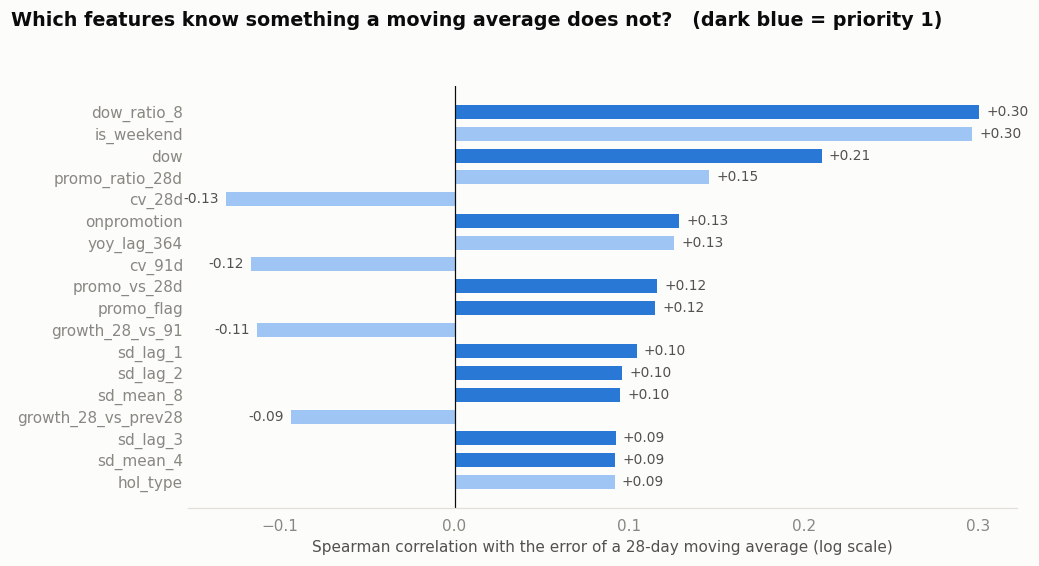

In [13]:
top = top_sur.head(18).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
cols = [BLUE if p == 1 else "#9ec5f4" for p in top.priority]
ax.barh(top.index, top.rho_surprise, color=cols, height=0.65)
for y, v in enumerate(top.rho_surprise): ax.text(v + (0.004 if v >= 0 else -0.004), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=INK2)
ax.axvline(0, color=fv.INK, lw=0.8); ax.grid(False); ax.set_xlabel("Spearman correlation with the error of a 28-day moving average (log scale)")
ax.tick_params(axis="y", length=0)
ftitle(fig, "Which features know something a moving average does not?   (dark blue = priority 1)")
finish(fig, "fe_screening")

**Insight.** A moving average is blind to the *day* it is forecasting, so the strongest "surprise" signals are calendar shape: `dow_ratio_8` (how strong this weekday is for this particular series, rho +0.30), `is_weekend` (+0.30) and `dow` (+0.21). Next come the promotion features (`promo_ratio_28d`, `onpromotion`, `promo_vs_28d`, `promo_flag`; +0.12 to +0.15): a promotion means demand above the series' own norm. The volatility features (`cv_28d`, `cv_91d`) are *negatively* related to the surprise (-0.13 / -0.12): the more erratic a series, the more a plain average over-forecasts it, so the model can use volatility to shade forecasts down. The year-ago value and the 28-vs-91-day trend (`yoy_lag_364`, `growth_28_vs_91`) complete the list.
By level, everything is dominated by the size of the series (rho ~ 0.97 for all `sd_*` / `roll_*` / `sf_mean_*` features - they are near-duplicates of each other).

This supports the tiers: horizon-aligned lags + rolling means (the level) + weekday shape + promotion + holidays first; volatility, growth, store/family context second; transactions, oil, city/state, store age and `year` are ablation candidates whose value must be *proven* by an experiment. (`is_weekend` stays tier 2 only because it is a deterministic function of `dow`, which trees can already split on; it is useful for linear or shallow models.)

### Recommended test order for Phase 4

| round | feature set | question it answers |
|---|---|---|
| 0 | **Baselines** (`sd_lag_1`, `sd_mean_4`, `roll_mean_28d`, + `rule_zero`) | what does a model have to beat? |
| 1 | **Tier 1** (29 features): horizon, weekday, pay-day, store/family ids, `sd_*`, `dow_ratio_8`, `roll_mean_7/14/28d`, `lag_1d/7d/14d`, promo (`onpromotion`, `promo_flag`, `promo_vs_28d`), holiday flags, zero-rate / days-since-last-sale, `yoy_mean_15d` | is a simple, explainable feature set already good? |
| 2 | **Tier 1 + 2** (all except tier 3) | do volatility / growth / store / family context help? Check with per-family error. |
| 3 | **Tier 2 + each tier-3 group** added one at a time (transactions, oil, city/state/store age, year) | does any of them earn its place? Keep only what improves >= 4 of 5 folds. |

Group-level ablation (drop a whole group, re-score) is more informative than single-feature importance here, because many features are near-duplicates (`roll_mean_28d` / `sd_mean_8` / `sf_mean_91d`).

In [14]:
# Distribution shift check for the promotion feature (risk R4): coverage by calendar year vs the real test window
idx_all = np.arange(len(P.dates)); rows = []
promotable = np.nansum(P.P[P.date_idx("2017-01-01"):Tt] > 0, axis=(0, 1)) > 0            # families ever promoted in 2017 (BOOKS is never promoted)
def cover(m):
    x = P.P[m][:, :, promotable]; ok = ~np.isnan(x); return np.mean(x[ok] > 0), np.mean(x[ok & (x > 0)])
for y in range(2013, 2018):
    rows.append((str(y),) + cover((P.dates.year == y) & (idx_all < Tt) & (~P.dec25)))
rows.append(("test window (Aug 16-31, 2017)",) + cover(idx_all >= Tt))
pd.DataFrame(rows, columns=["period", "share of store x family x day with a promotion", "mean items on promo (when > 0)"]).set_index("period")

,share of store x family x day with a promotion,mean items on promo (when > 0)
period,,
2013,0.000,NaN
2014,0.103,7.066
2015,0.215,8.036
2016,0.361,15.416
2017,0.467,15.020
"test window (Aug 16-31, 2017)",0.455,15.801


**Insight - promotion drift.** Promotion coverage grew from 0% of store x family x day cells in 2013 to 10% (2014), 22% (2015), 36% (2016) and 47% (2017); the test window sits at 45.5%, and the average promo count per promoted cell doubled between 2015 and 2016 (8 -> 15 items). A model trained on 2013-2014 would learn "promotions are rare and exceptional"; in the test window they are the norm. This is why the recommended training start is **2015-07-01** (with 2014-09-01 as a stated experiment) and why the relative feature `promo_vs_28d` is tier 1 next to the absolute count.

## 9. Validation strategy - a time-based backtest that mimics the real 16-day forecast

**Principle:** a validation fold is *one real forecast*: pick a Tuesday origin, hide everything after it, predict the next 16 days, score against what happened. Repeat for several origins and average. No random split, ever.

**Design**

* **Five folds**, all Tuesdays, chosen to cover different conditions: `F1_seasonal_twin` (2016-08-16: the same back-to-school season as the real test window, one year earlier), `F2_holiday_heavy` (2017-04-04, window includes Good Friday), `F3_mid_2017`, `F4_recent`, `F5_latest` (2017-07-25, the last origin whose 16 targets are all observed).
* **Training rows for a fold:** origins in `[2015-07-01, validation origin - 16 days]`. The 16-day *embargo* guarantees every training target is dated **before** the validation origin, so no label from the validation period (nor any information newer than the validation origin) is seen in training.
* **Expanding window** (train start fixed, end moves forward) - like retraining every week in production.
* **Metric:** RMSLE on all scored rows (the competition metric; it equals RMSE on the `log1p` target, so models should be trained on `y_log1p`). Mean of the five folds; also report the spread (std) and per-family RMSLE to see *where* a model is weak. `rule_zero` rows are **scored** (predicted as 0), so a model is never rewarded for improving only the easy part.
* **Final model:** after model selection, re-fit on all origins (including the two partial-horizon ones) and predict origin 2017-08-15.

In [15]:
rows = []
for name, vo in fv.FOLD_ORIGINS.items():
    trm, vam = fv.split_fold(mt, vo)
    trd, vad = mt.loc[trm, ["origin_date", "target_date", "rule_zero"]], mt.loc[vam, ["origin_date", "target_date", "horizon"]]
    assert trd.target_date.max() < pd.Timestamp(vo), "embargo violated"
    assert (vad.origin_date == vo).all() and vad.horizon.nunique() == 16
    assert not (trm & vam).any()
    rows.append({"fold": name, "validation origin": vo, "validation targets": f"{vad.target_date.min().date()} -> {vad.target_date.max().date()}",
                 "training origins": f"{trd.origin_date.min().date()} -> {trd.origin_date.max().date()}", "latest training target": trd.target_date.max().date(),
                 "gap (days)": (pd.Timestamp(vo) - trd.target_date.max()).days,
                 "train rows": len(trd), "train rows modeled (rule_zero=0)": int((trd.rule_zero == 0).sum()), "validation rows": len(vad)})
folds = pd.DataFrame(rows).set_index("fold")
print("All embargo assertions passed: no training target is dated on/after its validation origin.")
folds.style.format({"train rows": "{:,.0f}", "train rows modeled (rule_zero=0)": "{:,.0f}", "validation rows": "{:,.0f}"})

All embargo assertions passed: no training target is dated on/after its validation origin.


,validation origin,validation targets,training origins,latest training target,gap (days),train rows,train rows modeled (rule_zero=0),validation rows
fold,,,,,,,,
F1_seasonal_twin,2016-08-16,2016-08-17 -> 2016-09-01,2015-07-07 -> 2016-07-26,2016-08-11,5,"1,490,715","1,436,840","26,272"
F2_holiday_heavy,2017-04-04,2017-04-05 -> 2017-04-20,2015-07-07 -> 2017-03-14,2017-03-30,5,"2,380,288","2,287,952","27,984"
F3_mid_2017,2017-05-30,2017-05-31 -> 2017-06-15,2015-07-07 -> 2017-05-09,2017-05-25,5,"2,604,688","2,503,088","28,512"
F4_recent,2017-07-11,2017-07-12 -> 2017-07-27,2015-07-07 -> 2017-06-20,2017-07-06,5,"2,775,760","2,666,992","28,512"
F5_latest,2017-07-25,2017-07-26 -> 2017-08-10,2015-07-07 -> 2017-07-04,2017-07-20,5,"2,832,784","2,721,504","28,512"


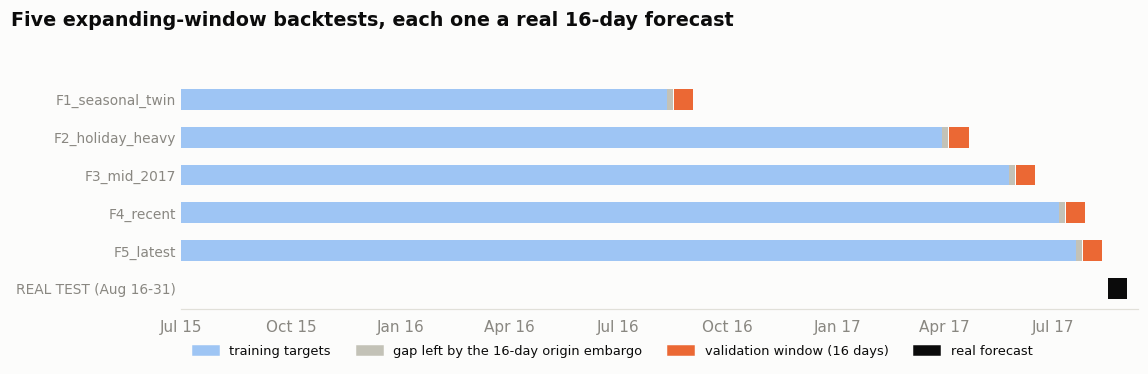

In [16]:
import matplotlib.dates as mdates
fig, ax = plt.subplots(figsize=(10.5, 3.6))
for i, (name, vo) in enumerate(fv.FOLD_ORIGINS.items()):
    vo = pd.Timestamp(vo); trm, _ = fv.split_fold(mt, vo); last_tr = mt.target_date[trm].max()
    ax.barh(i, (last_tr - pd.Timestamp("2015-07-01")).days, left=mdates.date2num(pd.Timestamp("2015-07-01")), color="#9ec5f4", height=0.55)
    ax.barh(i, (vo - last_tr).days, left=mdates.date2num(last_tr), color="#c3c2b7", height=0.55)
    ax.barh(i, 16, left=mdates.date2num(vo + pd.Timedelta(days=1)), color=ORANGE, height=0.55)
ax.barh(len(fv.FOLD_ORIGINS), 16, left=mdates.date2num(P.dates[Tt]), color=fv.INK, height=0.55)
ax.set_yticks(range(len(fv.FOLD_ORIGINS) + 1)); ax.set_yticklabels(list(fv.FOLD_ORIGINS) + ["REAL TEST (Aug 16-31)"], fontsize=9)
ax.invert_yaxis(); ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.grid(False); ax.tick_params(axis="y", length=0); ax.set_xlim(mdates.date2num(pd.Timestamp("2015-07-01")), mdates.date2num(pd.Timestamp("2017-09-10")))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#9ec5f4", label="training targets"), Patch(color="#c3c2b7", label="gap left by the 16-day origin embargo"), Patch(color=ORANGE, label="validation window (16 days)"), Patch(color=fv.INK, label="real forecast")],
          loc="lower left", fontsize=8.5, frameon=False, ncol=4, bbox_to_anchor=(0, -0.26))
ftitle(fig, "Five expanding-window backtests, each one a real 16-day forecast")
finish(fig, "fe_folds")

### Sanity-check the design with three no-model baselines

These are *not* models - they are columns of the table read as forecasts. They prove the folds are scoreable, expose how much the zero rule is worth, and give Phase 4 a bar to beat. When a baseline is missing a value it falls back to `roll_mean_28d`, then to 0. Note that every moving-average baseline already forecasts exactly 0 for a dormant series (its own history is all zeros) - the zero rule matters for *machine-learning models*, which output small positive numbers for such series, not for these baselines.

In [17]:
def rmsle(y_log, pred): return float(np.sqrt(np.mean((np.log1p(np.clip(pred, 0, None)) - y_log) ** 2)))
def baselines(d):
    fb = d.roll_mean_28d.fillna(d.sd_mean_8).fillna(0)
    out = {"roll_mean_28d": fb, "sd_lag_1 (same weekday last week)": d.sd_lag_1.fillna(fb), "sd_mean_4 (mean of last 4 same weekdays)": d.sd_mean_4.fillna(fb)}
    return out
res = {}
for name, vo in fv.FOLD_ORIGINS.items():
    _, vam = fv.split_fold(mt, vo); vad = mt[vam]
    res[name] = {k: rmsle(vad.y_log1p.values, np.asarray(v)) for k, v in baselines(vad).items()}
bl = pd.DataFrame(res); bl["mean"] = bl.mean(axis=1); bl["std"] = bl[list(fv.FOLD_ORIGINS)].std(axis=1)
bl.style.format("{:.4f}").highlight_min(axis=0, color="#cde2fb")

,F1_seasonal_twin,F2_holiday_heavy,F3_mid_2017,F4_recent,F5_latest,mean,std
roll_mean_28d,0.4739,0.4791,0.5083,0.4694,0.5222,0.4906,0.0233
sd_lag_1 (same weekday last week),0.5572,0.7161,0.5416,0.5160,0.5943,0.5850,0.0786
sd_mean_4 (mean of last 4 same weekdays),0.4667,0.4634,0.4711,0.4387,0.5063,0.4693,0.0242


In [18]:
# where is the naive forecast weak?  error by horizon bucket and by family (all five folds pooled) for the best baseline
pool = pd.concat([mt[fv.split_fold(mt, vo)[1]] for vo in list(fv.FOLD_ORIGINS.values())]).reset_index(drop=True)
pool["pred"] = baselines(pool)["sd_mean_4 (mean of last 4 same weekdays)"]; pool["se"] = (np.log1p(np.clip(pool.pred, 0, None)) - pool.y_log1p) ** 2
hb = pool.groupby(pd.cut(pool.horizon, [0, 4, 8, 12, 16], labels=["h 1-4", "h 5-8", "h 9-12", "h 13-16"])).se.mean().pow(0.5)
print("RMSLE of the best baseline by horizon bucket:", hb.round(4).to_dict())
fam_err = pool.groupby("family_id").se.mean().pow(0.5).rename(lambda i: P.fams[i]).sort_values(ascending=False)
print("\nhardest families for the baseline (RMSLE):"); print(fam_err.head(6).round(3).to_string())
print("easiest:", fam_err.tail(3).round(3).to_dict())

RMSLE of the best baseline by horizon bucket: {'h 1-4': 0.4496999979019165, 'h 5-8': 0.46230000257492065, 'h 9-12': 0.48089998960494995, 'h 13-16': 0.48559999465942383}

hardest families for the baseline (RMSLE):
family_id
SCHOOL AND OFFICE SUPPLIES   1.103
LINGERIE                     0.713
GROCERY II                   0.656
HARDWARE                     0.606
CELEBRATION                  0.604
HOME AND KITCHEN I           0.566
easiest: {'BREAD/BAKERY': 0.17499999701976776, 'DAIRY': 0.1599999964237213, 'PRODUCE': 0.14499999582767487}


**Insight - what the baselines tell us.** (1) The best no-model forecast is the mean of the last four same weekdays (`sd_mean_4`, mean RMSLE 0.469); the popular "same weekday last week" (`sd_lag_1`) is clearly worse (0.585) and unstable across folds (std 0.079 - it is hurt by single-week promotions and holidays), and a 28-day moving average (0.491) ignores the weekday pattern. **Phase 4 has to beat ~0.47.** (2) Error grows with horizon, but only gently (RMSLE 0.450 at h 1-4 -> 0.486 at h 13-16): the level of most series is stable over two weeks, which is why direct multi-horizon rows with horizon-aligned lags work. (3) By family the naive forecast fails on seasonal and low-volume lines - `SCHOOL AND OFFICE SUPPLIES` (1.10 - the back-to-school peak), `LINGERIE`, `GROCERY II`, `HARDWARE`, `CELEBRATION` - and is excellent on staples (`PRODUCE` 0.15, `DAIRY` 0.16, `BREAD/BAKERY` 0.17). Phase 4 must report error *by family*, not only the pooled score, and the school-supplies peak is where features such as `yoy_mean_15d`, `week_of_year` and holiday/event flags have to prove their worth.
(4) The five folds differ noticeably (0.44 to 0.51 for the best baseline; F5, the latest window, is the hardest at 0.506 and F4 the easiest at 0.439), and the weaker baselines swing much more (`sd_lag_1` reaches 0.72 in the Good-Friday fold F2), so a single fold would give a misleading picture - always average over folds and look at the spread.

## 10. Ready for Phase 4: baseline vs Random Forest vs LightGBM / XGBoost

One table serves all three model families. The differences are only in how they read it:

| | baseline | Random Forest (scikit-learn) | LightGBM / XGBoost |
|---|---|---|---|
| features | `sd_lag_1`, `sd_mean_4`, `roll_mean_28d` | tier 1 -> tier 1+2 | tier 1 -> tier 1+2 (+ tier 3 ablations) |
| NaN | fallback chain (above) | **fill with -1** (a value outside the sales range; works with every scikit-learn version) | keep NaN (native handling) |
| categorical | - | keep integer codes (ids are ordinal-free but forests cope) | pass `categorical` list to LightGBM; XGBoost `enable_categorical` |
| target | - | `y_log1p` | `y_log1p` (squared error = RMSLE) |
| rows | all (rule applied) | `rule_zero == 0` only | `rule_zero == 0` only |

`model_config.json` records all of this so Phase 4 can start with two lines of code.

In [19]:
tier = lambda k: fd[fd.priority <= k].feature.tolist()
CAT = [c for c in ["store_nbr", "family_id", "store_type", "store_cluster", "city_id", "state_id", "hol_type", "event", "dow"] if c in FEATURES]
cfg = {"target": "y_log1p", "target_raw_units": "y", "row_filter_for_training": "rule_zero == 0",
       "post_rule": "rows with rule_zero == 1 are forecast as 0 units",
       "keys": ["origin_date", "target_date", "store_nbr", "family_id", "horizon"], "test_id_column": "id",
       "features_all": FEATURES, "features_tier1": tier(1), "features_tier1_2": tier(2), "features_tier3_ablation": fd[fd.priority == 3].feature.tolist(),
       "categorical": CAT, "nan_policy": {"lightgbm_xgboost": "keep NaN", "random_forest": "fill -1"},
       "train_start": "2015-07-01", "train_start_extended_experiment": "2014-09-01", "embargo_days": fv.HORIZON,
       "folds": fv.FOLD_ORIGINS, "metric": "RMSLE = RMSE on y_log1p, all validation rows incl. rule_zero rows",
       "final_origin": str(P.dates[T_ORIGIN].date()), "final_refit_origins": "all origins incl. partial-horizon ones"}
json.dump(cfg, open("out/model_config.json", "w"), indent=2)

def get_xy(df, fold, features, rf=False):
    """Model-ready matrices for one fold: X/y of the modeled training rows, X of the modeled validation rows, and the
    full validation frame (rule_zero rows included) for scoring."""
    trm, vam = fv.split_fold(df, fv.FOLD_ORIGINS[fold])
    ok = df.rule_zero.values == 0
    Xtr, ytr = df.loc[trm & ok, features], df.loc[trm & ok, "y_log1p"]
    Xva, va = df.loc[vam & ok, features], df.loc[vam, ["store_nbr", "family_id", "horizon", "rule_zero", "y_log1p"]]
    if rf: Xtr, Xva = Xtr.fillna(-1), Xva.fillna(-1)
    return Xtr, ytr, Xva, va
import gc
del samp, pool; free_mem()
for fold in ["F1_seasonal_twin", "F5_latest"]:
    for nm, fs in [("tier 1", tier(1)), ("tier 1+2", tier(2))]:
        Xtr, ytr, Xva, va = get_xy(mt, fold, fs)
        print(f"{fold:17s} {nm:9s}: X_train {Xtr.shape} | X_valid (modeled rows) {Xva.shape} | scored rows {len(va):,} (rule_zero = {int(va.rule_zero.sum()):,}) | NaN cells in train {Xtr.isna().mean().mean():.1%}")
        del Xtr, ytr, Xva, va; gc.collect()
print(f"\ncounts: tier 1 = {len(tier(1))}, tier 1+2 = {len(tier(2))}, all = {len(FEATURES)} | categorical = {CAT}")

F1_seasonal_twin  tier 1   : X_train (1436840, 29) | X_valid (modeled rows) (25430, 29) | scored rows 26,272 (rule_zero = 842) | NaN cells in train 0.8%


F1_seasonal_twin  tier 1+2 : X_train (1436840, 78) | X_valid (modeled rows) (25430, 78) | scored rows 26,272 (rule_zero = 842) | NaN cells in train 0.9%


F5_latest         tier 1   : X_train (2721504, 29) | X_valid (modeled rows) (27248, 29) | scored rows 28,512 (rule_zero = 1,264) | NaN cells in train 0.5%


F5_latest         tier 1+2 : X_train (2721504, 78) | X_valid (modeled rows) (27248, 78) | scored rows 28,512 (rule_zero = 1,264) | NaN cells in train 0.6%

counts: tier 1 = 29, tier 1+2 = 78, all = 88 | categorical = ['store_nbr', 'family_id', 'store_type', 'store_cluster', 'city_id', 'state_id', 'hol_type', 'event', 'dow']


### Missing values in the final table (by feature)
Only features that are structurally undefined at some origins have NaN; each is either "not enough history" (year-ago values in the first year, growth ratios with a zero denominator) or "no valid days" - never a disguised zero. The year-ago features are the only ones with a large share of NaN in the whole table (27% at most) because the first year of history has no year-ago value; within the recommended training window this falls to 12-15%, and at the real origin to 6-10% (combinations that were masked - recording gaps - exactly one year earlier). Growth / volatility ratios are undefined (~4-6%) mainly for the dormant and never-sold combinations, i.e. rows the model does not train on anyway.

In [20]:
trw = (mt.origin_date >= "2015-07-01").values
nn = pd.DataFrame({"NaN share (whole table)": mt[FEATURES].isna().mean(), "NaN share (training window, origin >= 2015-07-01)": mt.loc[trw, FEATURES].isna().mean(),
                   "NaN share (real test origin)": tf[FEATURES].isna().mean()})
nn = nn[nn.iloc[:, :2].max(axis=1) > 0.005].sort_values("NaN share (whole table)", ascending=False)
nn["group"] = fd.set_index("feature").group.reindex(nn.index)
nn["why"] = nn.index.map(lambda c: "needs 364+ days of history" if c.startswith("yoy") else "ratio undefined when the denominator mean is 0" if c.startswith(("growth", "cv_", "store_growth", "store_tx_growth", "sf_share", "store_sales_per", "dow_ratio")) else "no valid observation in the window (masked / never sold)")
nn.style.format({c: "{:.1%}" for c in nn.columns[:3]})

,NaN share (whole table),"NaN share (training window, origin >= 2015-07-01)",NaN share (real test origin),group,why
yoy_trend_28d,27.1%,15.4%,9.5%,I. Growth & year-ago,needs 364+ days of history
yoy_lag_364,24.4%,14.1%,7.9%,I. Growth & year-ago,needs 364+ days of history
yoy_mean_15d,22.7%,12.1%,6.5%,I. Growth & year-ago,needs 364+ days of history
growth_28_vs_prev28,5.5%,5.8%,6.1%,I. Growth & year-ago,ratio undefined when the denominator mean is 0
growth_7_vs_28,4.5%,5.4%,6.4%,I. Growth & year-ago,ratio undefined when the denominator mean is 0
cv_28d,4.5%,5.4%,6.4%,H. Volatility,ratio undefined when the denominator mean is 0
growth_28_vs_91,3.5%,4.3%,4.6%,I. Growth & year-ago,ratio undefined when the denominator mean is 0
cv_91d,3.5%,4.3%,4.6%,H. Volatility,ratio undefined when the denominator mean is 0
dow_ratio_8,3.5%,4.3%,4.6%,F. Horizon-aligned same-weekday lags,ratio undefined when the denominator mean is 0
sf_age_days,2.4%,2.7%,3.0%,J. Activity & intermittency,no valid observation in the window (masked / never sold)


## 11. Phase 3 summary - what is ready for Phase 4

In [21]:
trw = (mt.origin_date >= "2015-07-01").values
summ = pd.DataFrame([
    ("Modeling table", f"{len(mt):,} rows x {mt.shape[1]} columns ({len(FEATURES)} features + keys, target, rule flag) - `out/modeling_table.parquet` ({os.path.getsize('out/modeling_table.parquet') / 1e6:,.0f} MB)"),
    ("Granularity", f"{mt.origin_date.nunique()} weekly (Tuesday) forecast origins x 16 horizons x 54 stores x 33 families; targets {mt.target_date.min().date()} -> {mt.target_date.max().date()}"),
    ("Recommended training window", f"origin >= 2015-07-01: {trw.sum():,} rows, of which {int((mt.rule_zero[trw] == 0).sum()):,} are modeled (rule_zero = 0)"),
    ("Target", "`y_log1p` = log(1 + unit sales); RMSE on it equals the competition metric (RMSLE)"),
    ("Real forecast features", f"`out/test_features.parquet`: {len(tf):,} rows = 16 days x 1,782 series, origin {tf.origin_date.iloc[0].date()}, `id` aligned with sample_submission"),
    ("Zero-demand handling", f"masked zeros removed; `rule_zero` = 1 for {int(tf.rule_zero.sum() / 16)} dormant / never-sold combinations at the real origin (forecast 0 by rule)"),
    ("Leakage audit", "poison-the-future test passed on 3 origins x 2 corruptions (features bit-identical); control test proves it can detect leakage; index arithmetic asserted for all 16 horizons"),
    ("Validation", "5 expanding-window Tuesday-origin folds, 16-day embargo asserted; naive baseline to beat: RMSLE ~0.47 (`sd_mean_4`)"),
    ("Feature priorities", f"tier 1 = {len(tier(1)) if 'tier' in globals() else int((fd.priority == 1).sum())} features (test first), tier 1+2 = {int((fd.priority <= 2).sum())}, tier 3 = {int((fd.priority == 3).sum())} ablation candidates"),
], columns=["item", "status"]).set_index("item")
summ.style.set_properties(**{"text-align": "left", "white-space": "normal"})

,status
item,
Modeling table,"4,918,427 rows x 93 columns (88 features + keys, target, rule flag) - `out/modeling_table.parquet` (187 MB)"
Granularity,228 weekly (Tuesday) forecast origins x 16 horizons x 54 stores x 33 families; targets 2013-04-03 -> 2017-08-15
Recommended training window,"origin >= 2015-07-01: 2,955,742 rows, of which 2,839,036 are modeled (rule_zero = 0)"
Target,`y_log1p` = log(1 + unit sales); RMSE on it equals the competition metric (RMSLE)
Real forecast features,"`out/test_features.parquet`: 28,512 rows = 16 days x 1,782 series, origin 2017-08-15, `id` aligned with sample_submission"
Zero-demand handling,masked zeros removed; `rule_zero` = 1 for 80 dormant / never-sold combinations at the real origin (forecast 0 by rule)
Leakage audit,poison-the-future test passed on 3 origins x 2 corruptions (features bit-identical); control test proves it can detect leakage; index arithmetic asserted for all 16 horizons
Validation,"5 expanding-window Tuesday-origin folds, 16-day embargo asserted; naive baseline to beat: RMSLE ~0.47 (`sd_mean_4`)"
Feature priorities,"tier 1 = 29 features (test first), tier 1+2 = 78, tier 3 = 10 ablation candidates"


**Design decisions worth defending in an interview**

1. **Direct multi-horizon rows** with horizon-aligned same-weekday lags, instead of a recursive one-step model: no error accumulation, and training looks exactly like production.
2. **Zeros are not one thing.** Store-not-open, closures, recording outages and 25-Dec are *missing*, dormant series get a transparent rule, and only genuine zeros of live series reach the model.
3. **One code path** builds training rows and the real test features (`FeatureBuilder.origin_table`), and a poison test proves that nothing dated after the origin can influence a feature.
4. **Validation mirrors deployment** - weekly origins, 16-day horizon, embargo, expanding window, five different conditions (including last year's back-to-school season, the same season as the test window).
5. **Honest limits:** promotion coverage drifts over time (mitigated by the training window and relative promo features); the offline cleaning masks use full-history definitions (documented risk R3, low); the two most recent origins are partial-horizon and used only for the final re-fit.

**Next (Phase 4 - not started here):** score the baseline, Random Forest and LightGBM/XGBoost on the same five folds with feature tiers 1 -> 1+2 -> ablations, report RMSLE by fold, horizon and family, then re-fit the winner on all origins and predict `test_features.parquet`.